## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('./ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

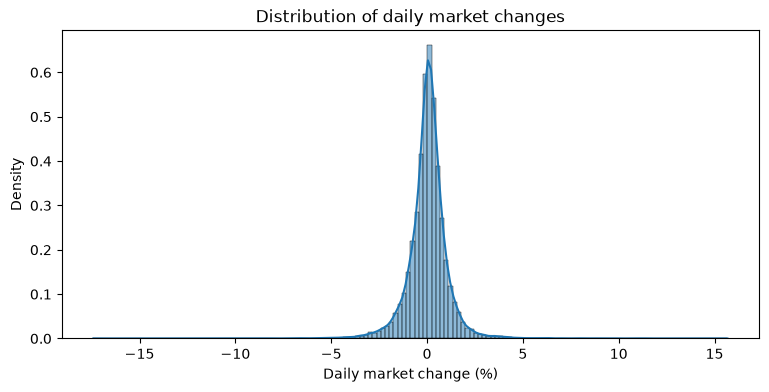

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

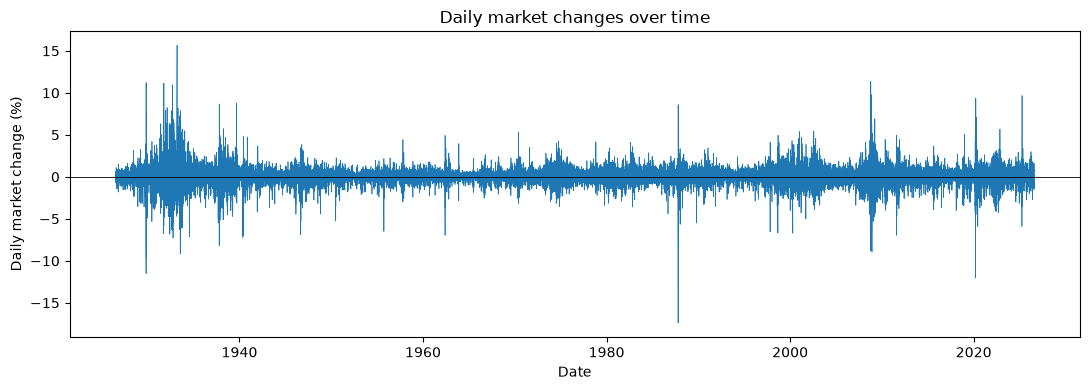

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [5]:
df['r_t'] = df['market_return_pct']
df['r_tp1'] = df['market_return_pct'].shift(-1) #shift into the future

df['y_t'] = (df['r_t'] > 0).map({False: 'Down', True: 'Up'})

df['y_tp1'] = df['y_t'].shift(-1)

pd.crosstab(df['y_t'],df['y_tp1'])

y_tp1,Down,Up
y_t,,
Down,5909,5999
Up,5999,8388


In [6]:
tab = pd.crosstab(df['y_t'], df['y_tp1'],
                  normalize=True, margins=True) #joint pmf and marginals

tab

y_tp1,Down,Up,All
y_t,,,
Down,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


Looking at the above, up transitions are more common: the next day is Up 54.7% of the time vs. 45.3% Down. Up -> Up is the most common pair at 31.9%, and Down -> Down is the least common at 22.5%. 

Moreover, an Up day is more likely after an Up day: P(Up | Up) = 0.583 vs. P(up | Down) = 0.504. After a Down day, the next day is essentially akin to a coin flip.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [7]:
df['bin'] = pd.cut(
    df['market_return_pct'],
    bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf],
    labels = ['Large loss', 'Small Loss', 'Near Zero', 'Small Gain', 'Large Gain']
)

df['y_t'] = df['bin']

df['y_tp1'] = df['bin'].shift(-1)

df['bin'].value_counts()

bin
Small Gain    9785
Small Loss    7452
Near Zero     3441
Large Gain    2859
Large loss    2759
Name: count, dtype: int64

In [8]:
tab = pd.crosstab(df['y_t'], df['y_tp1'],
                  normalize=True, margins=True) #joint pmf and marginals

tab

y_tp1,Large loss,Small Loss,Near Zero,Small Gain,Large Gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small Loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near Zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small Gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large Gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


In [9]:
df.groupby('y_t', observed=False)['r_tp1'].describe()

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small Loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near Zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small Gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large Gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


For bin counts, small gain is the most common at 9785, then small loss at 7452, then near zero at 3441, then large gain at 2589, and then large loss is least common at 2759.

For joint pmf: small gain -> small gain is the most likely transition at 0.159, followed by small gain -> small loss at 0.100, then small loss -> small gain at 0.098, and then small loss -> small loss at 0.089. Small moves followed by small moves account for nearly half of all the pairs.


Conditional PMF and the top two next states:

| Today | Most likely | Second most likely |
| --- | --- | --- |
| Large loss | Small gain (0.27) | Small loss (0.26) |
| Small loss | Small gain (0.35) | Small loss (0.31) |
| Near zero | Small gain (0.38) | Small loss (0.32) |
| Small gain | Small gain (0.43) | Small loss (0.27) |
| Large gain | Small gain (0.35) | Small loss (0.23) |

Looking at the above, the large loss is closest to being uniform. The other rows put around 60-70% on small gain/small loss, but that mostly matches the marginal PMF rather than today's state. Every row's most likely next state is small gain, with probability at most 0.43. Overall, the next state is difficult to predict.

Conditional expectation: exepected returns for tomorrow are all close to 0, with -0.04% after a large loss or small loss, 0.02% after near zero, 0.11% after small gain, and 0.16% after large gain.

For min/max and volatility, the range is widest after large moves (large loss: -17.4 to 11.2; large gain: -12.0 to 15.7) and more narrow after nzero zero (-8.2 to 5.5). The standard deviation is highest after a large loss (1.72) and a large gain (1.38), compared with around 0.83 after near zero or small gain. This is thus volatility clustering, where a big move in either one of the directions tends to be followed by another big move, though the actual sign of that move is unpredictable. Overall, volatility is highest after losses.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [16]:
n_bins = 21

df['y_t'] = pd.qcut(df['market_return_pct'], q=n_bins, labels=False)

df['y_tp1'] = df['y_t'].shift(-1).astype('Int64')



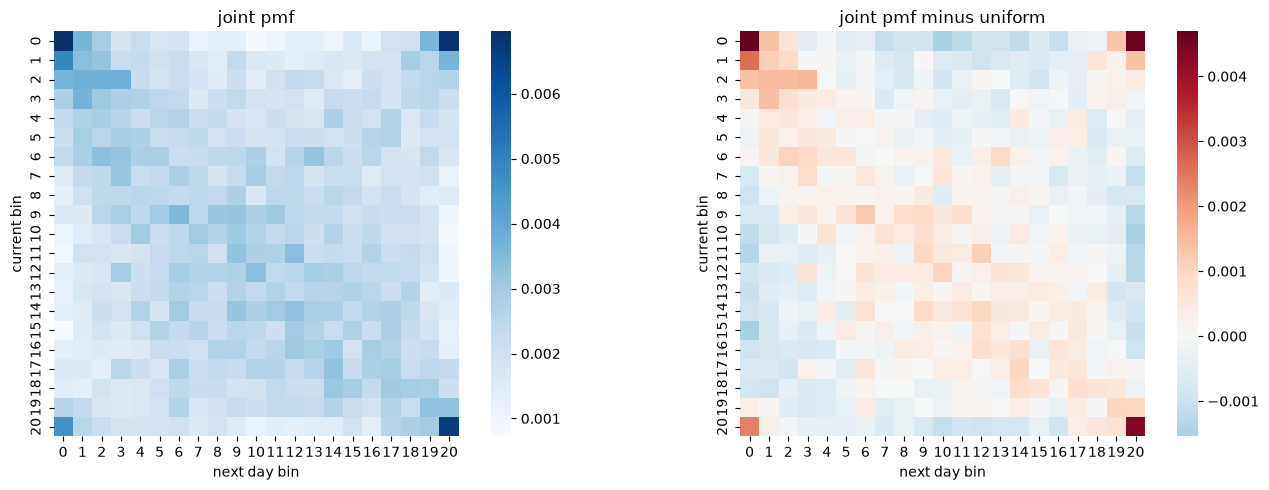

In [14]:
tab = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True) #joint pmf

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(tab, cmap='Blues', square=True, ax=axes[0])

axes[0].set(title='joint pmf', xlabel='next day bin', ylabel='current bin')

sns.heatmap(tab - 1/n_bins**2, cmap='RdBu_r', center=0, square=True, ax=axes[1])

axes[1].set(title='joint pmf minus uniform', xlabel = 'next day bin', ylabel='current bin')

fig.tight_layout()

plt.show()

The raw joint PMF appears mostly uniform except for the four dark corners (bin 0/20 -> bin 0/20). After subtracting 1/21^2, those corners are the strongest red: extreme days are followed by extreme days in either direction. Apart from the cells next to the corners, rows and columns 0 and 20 are mostly blue, so extreme days pair with middle days less often than uniform, and the middle of the table is light red, so small moves tend to follow small moves.

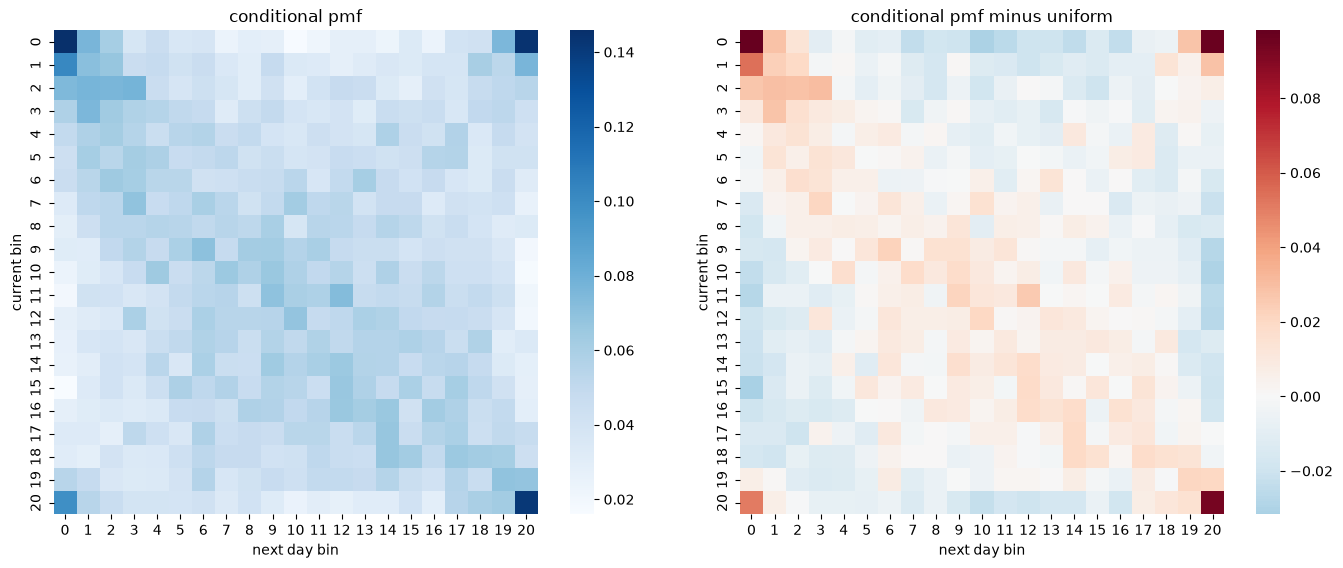

In [15]:
tab = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')  #conditional pmf

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(tab, cmap='Blues', square=True, ax=axes[0])

axes[0].set(title='conditional pmf', xlabel='next day bin', ylabel='current bin')

sns.heatmap(tab - 1/n_bins, cmap='RdBu_r', center=0, square=True, ax=axes[1])

axes[1].set(title='conditional pmf minus uniform', xlabel = 'next day bin', ylabel='current bin')

fig.tight_layout()

plt.show()

The same pattern appears row by row. From bin 0, the darkest cells are bins 0 and 20, near the top of the color scale. From bin 20, bin 20 is darkest and bin 0 is next. After subtracting 1/21, the middle rows are paler (close to uniform), with slight red in the middle columns and blue in the extreme columns.

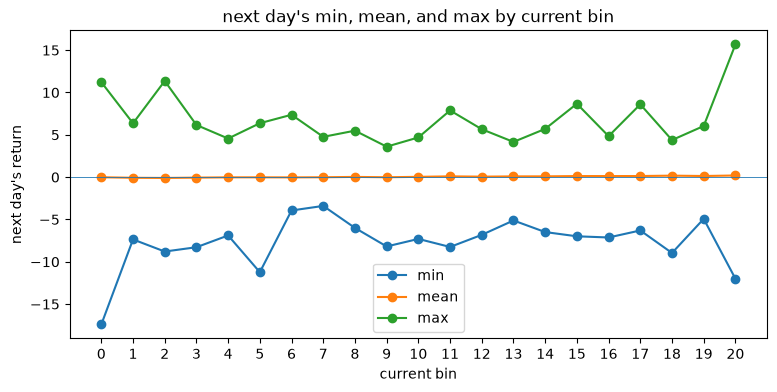

In [17]:
stats = df.groupby('y_t')['r_tp1'].agg(['min', 'mean', 'max', 'std'])


fig, ax = plt.subplots(figsize = (9, 4))

for col in ['min', 'mean', 'max']:
    ax.plot(stats.index, stats[col], marker = 'o', label=col)

ax.axhline(0, linewidth=0.6)

ax.set(xlabel='current bin', ylabel="next day's return",
       title = "next day's min, mean, and max by current bin", xticks=stats.index)

ax.legend()

plt.show()


The mean line is flat at around 0 across all 21 bins. At this scale, today's bin makes almost no visible different to tomorrow's average return. The min and max lines are much more jagged, with no steady trend across the middle bins. The widest gap between min and mix is after bins 0 and 20, and the lowest min around -17 follows bin 0, and the highest max just abovce 15 follows bin 20.

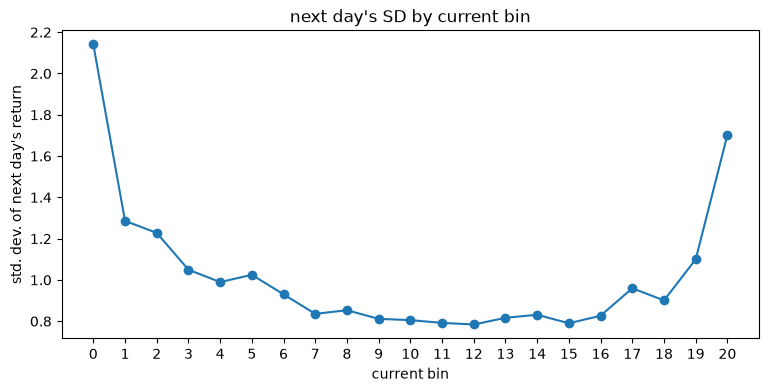

In [19]:



fig, ax = plt.subplots(figsize = (9, 4))


ax.plot(stats.index, stats['std'], marker='o')

ax.set(xlabel='current bin', ylabel="std. dev. of next day's return",
       title = "next day's SD by current bin", xticks=stats.index)



plt.show()


Looking at the above, the standard deviation appears U-shaped, and it is around 0.8 in bins 7-16, and rises to around 2.1 after bin 0 and 1.7 after bin 20. The left side is higher than the right side, so big losses are followed by more volatility than big gains -> volatility clustering.

In terms of how easy it is to predict the market, it is not easy, for the mean of tomorrow's return stays near 0 for ever bin, so today's bin tells us very little about direction. Only the size of the move (volatility) varies predictably with today's bin.